# NeuralOFDM - Classical OFDM baseline

## 1. Goal

In this notebook I build a simple **SISO QPSK OFDM** link and check that every part
works before moving on to LMMSE or neural networks. The actual code lives in the
`neural_ofdm` package; the notebook just calls it and shows the results.

`bits -> QPSK -> data/pilot grid -> IFFT -> CP -> FIR channel + AWGN -> remove CP -> FFT -> LS -> ZF -> bits -> BER`

**Assumptions:** perfect timing, whole-sample path delays, the channel stays the same
during each one-symbol frame, all FFT bins are used (no DC or guard nulls), and no
coding or synchronization. I haven't picked a sample rate, so samples and subcarriers
are just index numbers.

**To run it:** from the project folder run `uv sync` and then `uv run jupyter lab`,
pick the project's Python kernel and run all cells from a fresh kernel. Every random
number comes from a seeded generator.

In [1]:
import platform
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neural_ofdm import OFDMConfig
from neural_ofdm.channel import channel_frequency_response, fixed_channel
from neural_ofdm.estimation import ls_channel_estimate
from neural_ofdm.experiments import format_sweep_table, run_ber_sweep, save_sweep
from neural_ofdm.metrics import bit_error_rate, normalized_mean_squared_error
from neural_ofdm.modulation import qpsk_demodulate, qpsk_modulate, random_bits
from neural_ofdm.ofdm import (
    add_cyclic_prefix,
    build_resource_grid,
    ofdm_demodulate,
    ofdm_modulate,
    remove_cyclic_prefix,
)
from neural_ofdm.plotting import (
    plot_ber_sweep,
    plot_channel,
    plot_channel_estimate,
    plot_constellation,
    plot_cyclic_prefix,
    plot_nmse_sweep,
    plot_noise_examples,
    plot_resource_grid,
    plot_time_frequency,
)
from neural_ofdm.simulation import simulate_frame

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Start Jupyter from the project root."
DEMO_DIR = ROOT / "results" / "baseline_demo"
DEMO_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.unicode_minus": False})
SEED = 2026
print("Python:", platform.python_version(), "NumPy:", np.__version__, "Seed:", SEED)

Python: 3.12.13 NumPy: 2.5.3 Seed: 2026


## 2. Settings and conventions

The default grid has **64 bins, a 16-sample CP, 16 pilots and 48 QPSK data symbols**,
so 96 payload bits per frame. Pilots and data both have energy one. The settings
object can't be changed after it is created.

The signal IFFT/FFT use `norm="ortho"`, which puts a `1/sqrt(N)` in both directions and
keeps the total energy the same. For a channel with `L` taps the CP has to satisfy
`N_CP>= L-1`. The channel's frequency response is the **ordinary** FFT of its taps,
`H[k]=sum_l h[l]e^(-j2pi kl/N)`, and then the noiseless FFT output is `Y[k]=H[k]X[k]`.
If I used the unitary FFT for `h` too, every gain would come out `1/sqrt(N)` too small.

`snr_db` is the received sample power over the kept `N+N_CP` samples divided by the
total complex noise variance. It includes the CP and the start of the channel response,
leaves out the convolution tail, and is **not Eb/N0**. The CP and pilots cost
throughput, and I don't convert to energy per bit anywhere.

NumPy's [FFT normalization documentation](https://numpy.org/doc/stable/reference/routines.fft.html#normalization)
describes the transform scaling I use.

In [2]:
config = OFDMConfig(snr_db=15, random_seed=SEED)
for name, value in asdict(config).items():
    print(f"{name}: {value}")
print("Pilots:", config.pilot_indices)
print("Data bins:", config.data_indices)
print("Payload bits/frame:", config.bits_per_frame)

fft_size: 64
cp_length: 16
pilot_spacing: 4
pilot_value: (0.7071067811865475+0.7071067811865475j)
modulation_order: 4
snr_db: 15
random_seed: 2026
channel_model: fixed
channel_taps: ((1+0j), (0.35+0.15j), (0.12-0.1j))
rayleigh_powers: (1.0, 0.4, 0.15, 0.05)
channel: None
noise_mode: received_snr
reference_esn0_db: 20.0
pilot_values: None
Pilots: [ 0  4  8 12 16 20 24 28 32 36 40 44 48 52 56 60]
Data bins: [ 1  2  3  5  6  7  9 10 11 13 14 15 17 18 19 21 22 23 25 26 27 29 30 31
 33 34 35 37 38 39 41 42 43 45 46 47 49 50 51 53 54 55 57 58 59 61 62 63]
Payload bits/frame: 96


## 3. Bits and QPSK

QPSK sends two bits per complex symbol. I use
`s=((1-2b_I)+j(1-2b_Q))/sqrt(2)`, so every symbol has `|s|^2=1`.
Neighboring points differ in only one bit (Gray coding), so the most common symbol
error flips just one bit. The receiver decides each bit from the sign of the real or
imaginary part. If the bit order or the scaling were off, every later result would
be off too.

[1, 1] -> -0.7071-0.7071j
[0, 1] -> +0.7071-0.7071j
[0, 1] -> +0.7071-0.7071j
[1, 0] -> -0.7071+0.7071j
[1, 0] -> -0.7071+0.7071j
[1, 0] -> -0.7071+0.7071j
[0, 0] -> +0.7071+0.7071j
[1, 1] -> -0.7071-0.7071j
Mean symbol energy: 1.0


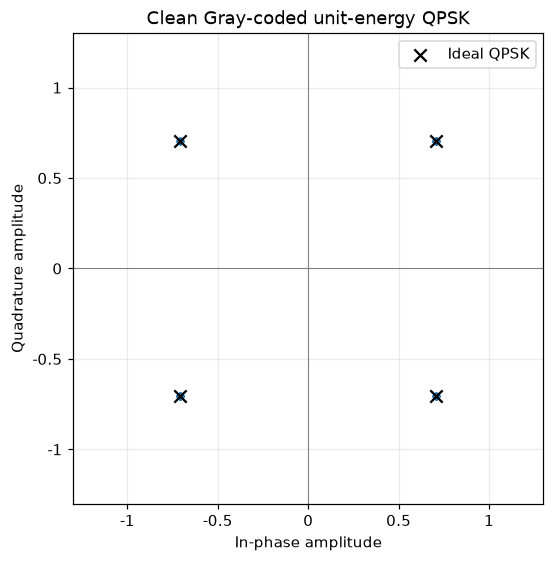

In [3]:
bits = random_bits(config.bits_per_frame, np.random.default_rng(SEED))
data_symbols = qpsk_modulate(bits)
for pair, symbol in zip(bits.reshape(-1, 2)[:8], data_symbols[:8], strict=True):
    print(f"{pair.tolist()} -> {symbol.real:+.4f}{symbol.imag:+.4f}j")
print("Mean symbol energy:", np.mean(np.abs(data_symbols) ** 2))
assert bit_error_rate(bits, qpsk_demodulate(data_symbols)) == 0
figure = plot_constellation(data_symbols, "Clean Gray-coded unit-energy QPSK")
figure.savefig(DEMO_DIR / "qpsk_clean.png", dpi=160)
plt.show()

## 4. OFDM resource grid

The grid puts one complex symbol on each frequency bin. Pilots are at bins
0, 4, 8, ..., 60 and data fills the rest. The transmitter and receiver both take these
positions from the same settings, so they can't get out of step (otherwise the
receiver would divide by "pilots" that were never sent).

I use every bin, including DC, to keep things simple. Guard bands or a DC null could
be added later in one place.

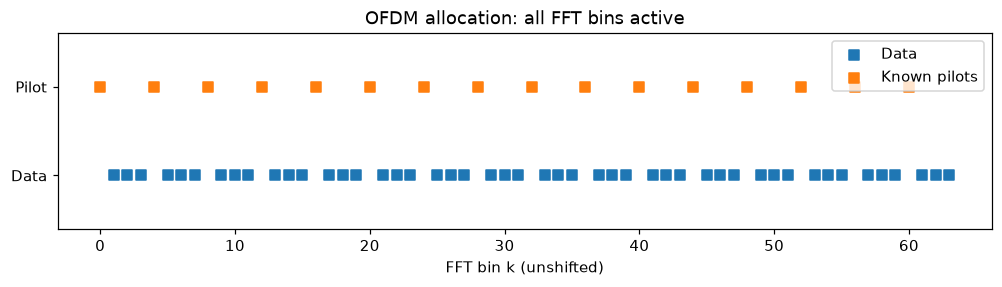

In [4]:
frequency_grid = build_resource_grid(data_symbols, config)
assert np.intersect1d(config.pilot_indices, config.data_indices).size == 0
figure = plot_resource_grid(config)
figure.savefig(DEMO_DIR / "resource_grid.png", dpi=160)
plt.show()

## 5. IFFT: from subcarriers to a waveform

The IFFT adds up `N` orthogonal complex sinusoids, each scaled by its grid value, and
that gives the time samples sent over the channel. The FFT at the receiver separates
them again. The time samples go up and down in size even though every QPSK symbol has
the same magnitude. The sinusoids only stay separate if the FFT window is lined up
correctly and is a full symbol long.

Frequency energy: 64.0
Time energy: 64.0


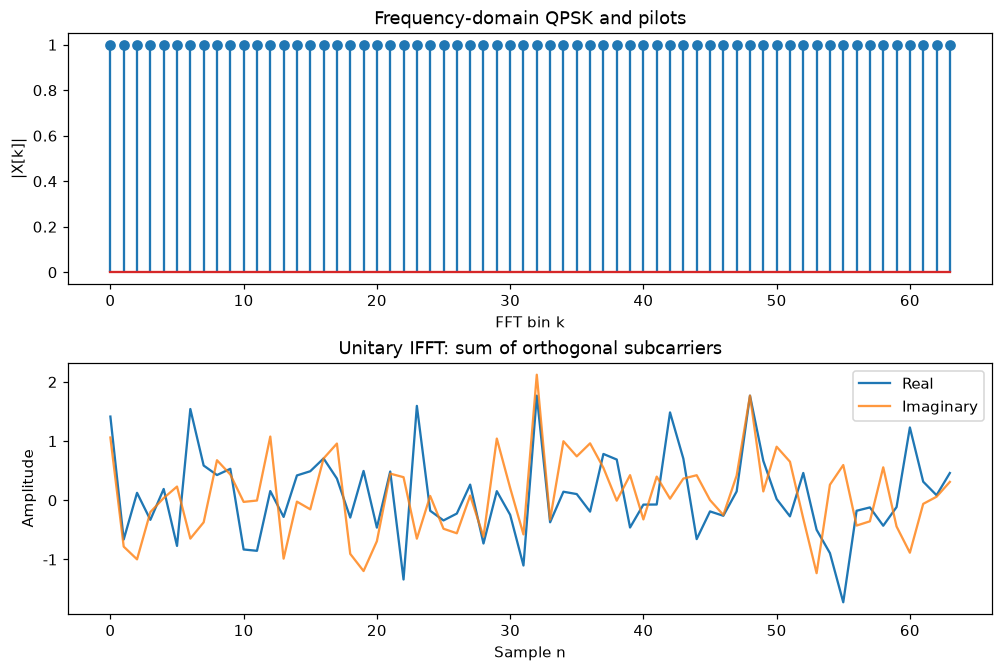

In [5]:
time_signal = ofdm_modulate(frequency_grid)
np.testing.assert_allclose(ofdm_demodulate(time_signal), frequency_grid, atol=1e-14)
print("Frequency energy:", np.sum(np.abs(frequency_grid) ** 2))
print("Time energy:", np.sum(np.abs(time_signal) ** 2))
figure = plot_time_frequency(frequency_grid, time_signal)
figure.savefig(DEMO_DIR / "time_frequency.png", dpi=160)
plt.show()

## 6. Cyclic prefix

Multipath means delayed copies of the signal reach the receiver. A copy delayed by
`l` samples needs samples from before the FFT window starts. Copying the end of the
symbol to its front (the CP) gives those samples, so after removing the CP the
convolution inside the window becomes a circular one. The FFT turns that into a
simple multiplication: one channel gain per bin.

If the CP is shorter than `L-1`, part of the previous symbol leaks into the window
and `Y=HX` no longer holds. The CP takes time and energy but carries no payload.

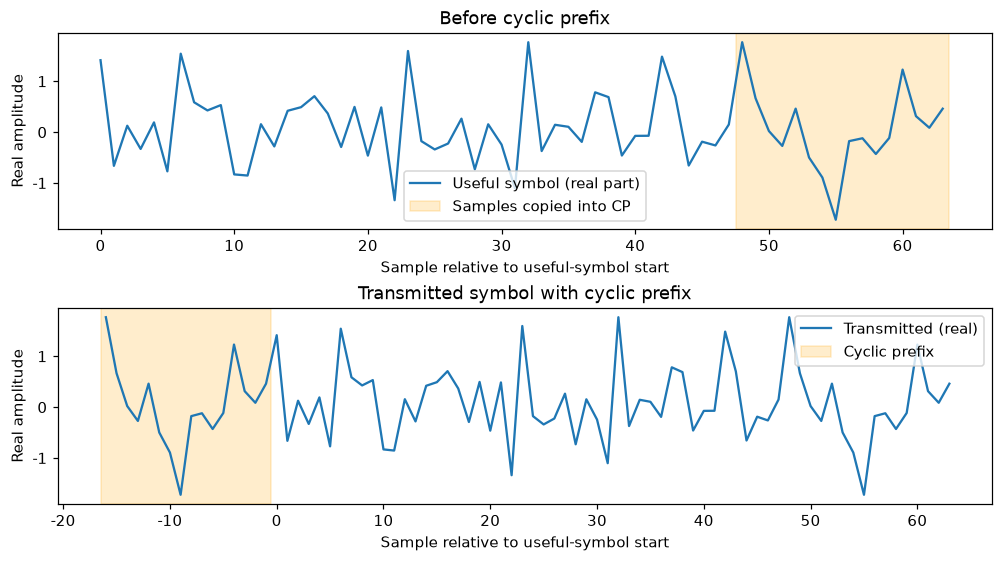

In [6]:
transmitted_signal = add_cyclic_prefix(time_signal, config.cp_length)
np.testing.assert_array_equal(
    remove_cyclic_prefix(transmitted_signal, config.cp_length, config.fft_size), time_signal
)
figure = plot_cyclic_prefix(time_signal, transmitted_signal, config.cp_length)
figure.savefig(DEMO_DIR / "cyclic_prefix.png", dpi=160)
plt.show()

## 7. Multipath channel

The fixed channel has a strong direct path and two weaker echoes at delays of 1 and
2 samples. I scale it so `sum_l|h[l]|^2=1`, keeping the relative sizes and phases.
That makes the average `|H[k]|^2` equal to one, but individual bins can be stronger
or weaker because the paths add up or cancel. If a bin is a true null its data is
gone, and dividing by a tiny number won't bring it back.

Tap energy: 0.9999999999999999
Minimum channel magnitude: 0.5049140278254202


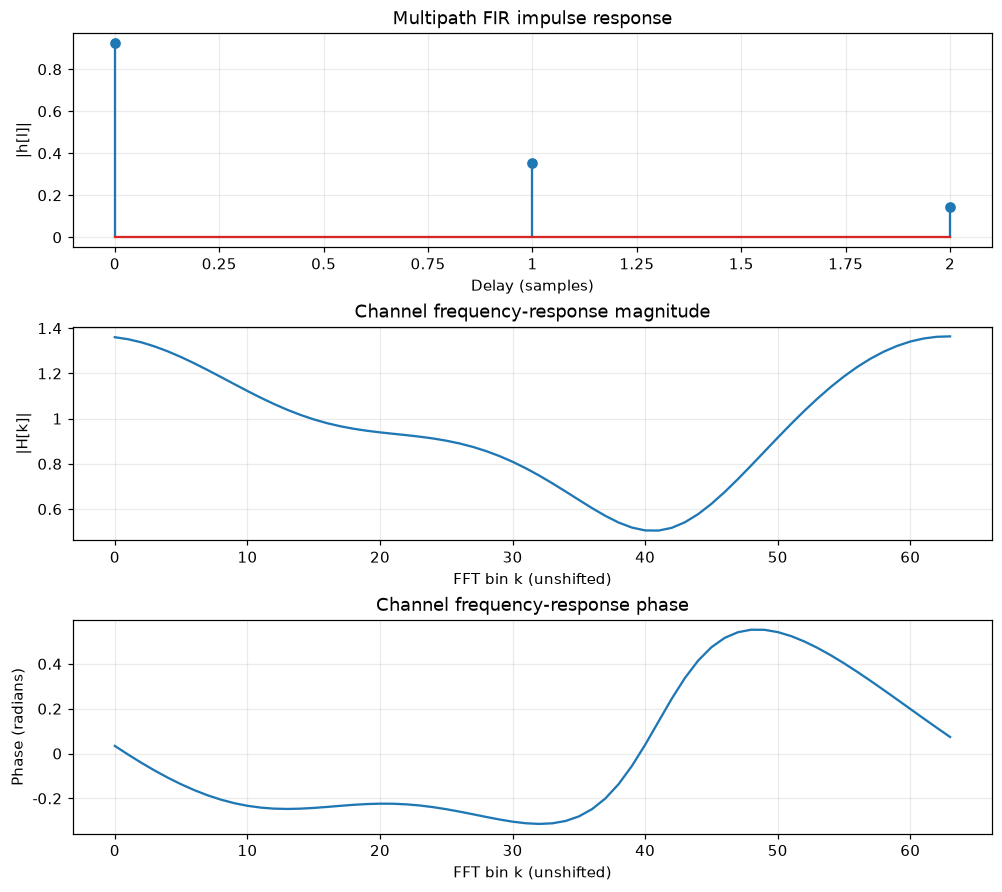

In [7]:
taps = fixed_channel(config.channel_taps)
true_channel = channel_frequency_response(taps, config.fft_size)
print("Tap energy:", np.sum(np.abs(taps) ** 2))
print("Minimum channel magnitude:", np.min(np.abs(true_channel)))
figure = plot_channel(taps, true_channel)
figure.savefig(DEMO_DIR / "channel.png", dpi=160)
plt.show()

## 8. Noise and the identity-channel check

For received power `P_r` and `gamma=10^(SNR_dB/10)`, I set
`sigma_w^2=P_r/gamma` and
`w=sqrt(sigma_w^2/2)(a+jb)` with independent `a,b~N(0,1)`.
So the real and imaginary parts each get half the noise variance. The unitary FFT
keeps the noise variance the same. In one short frame the actual SNR wobbles a bit;
I don't force it to be exact, because that would change the noise distribution.

These plots use an identity channel (no multipath) so only the noise shows up.

Identity channel, no noise: BER = 0.0


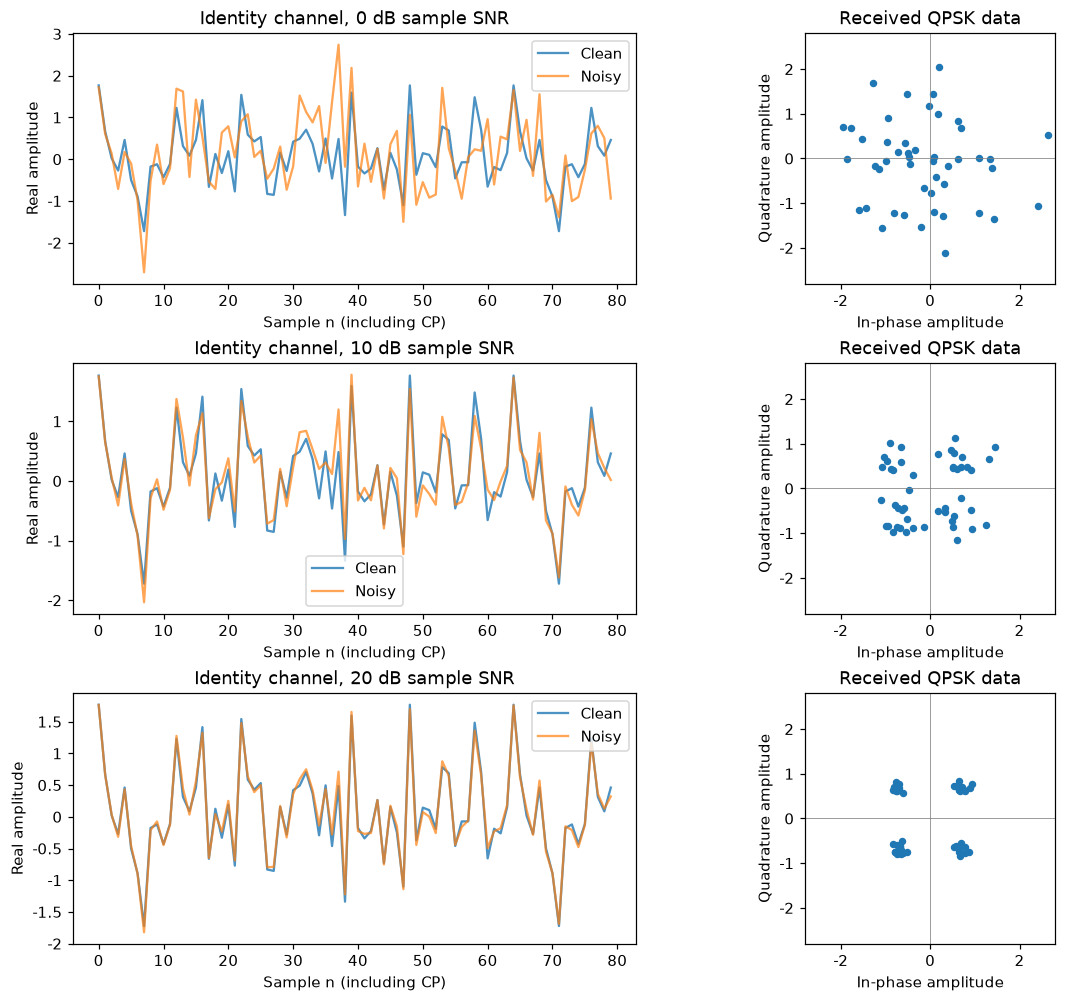

In [8]:
identity_config = replace(config, channel_taps=(1 + 0j,), cp_length=0, snr_db=np.inf)
identity_frame = simulate_frame(identity_config, np.random.default_rng(SEED), csi="perfect")
assert identity_frame.ber == 0
print("Identity channel, no noise: BER =", identity_frame.ber)
figure = plot_noise_examples(config, SEED)
figure.savefig(DEMO_DIR / "noise_examples.png", dpi=160)
plt.show()

## 9. Equalizing with perfect CSI

CSI stands for channel-state information. First I let the receiver use the true `H`
and apply zero forcing, `X_hat[k]=Y[k]/H[k]`. With no noise and a long enough CP this
has to give back the transmitted grid to rounding error. I don't trust any
channel-estimation result until this works.

ZF boosts the noise in weak bins. I clamp channel magnitudes below `10^(-10)` (keeping
the phase), print a warning and count how often it happens. This only stops a division
by zero; it can't recover a true null. For this fixed channel no bins need it.

Fixed multipath, perfect CSI, no noise: BER = 0.0


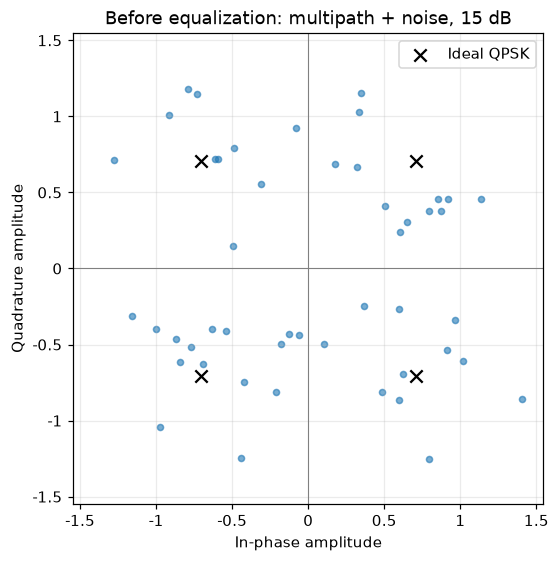

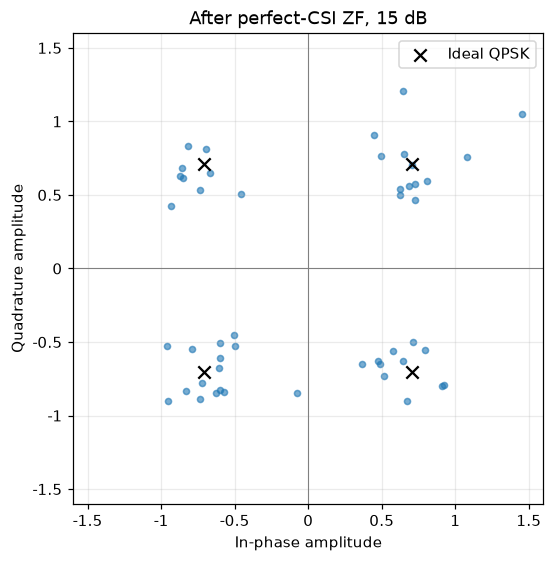

Stabilized bins: 0


In [9]:
noiseless = simulate_frame(
    replace(config, snr_db=np.inf), np.random.default_rng(SEED), csi="perfect"
)
assert noiseless.ber == 0
np.testing.assert_allclose(
    noiseless.received_grid,
    noiseless.channel_frequency_response * noiseless.frequency_grid,
    atol=1e-14,
)
np.testing.assert_allclose(noiseless.equalized_grid, noiseless.frequency_grid, atol=1e-14)
print("Fixed multipath, perfect CSI, no noise: BER =", noiseless.ber)

perfect_frame = simulate_frame(config, np.random.default_rng(SEED), csi="perfect")
figure = plot_constellation(
    perfect_frame.received_grid[config.data_indices],
    "Before equalization: multipath + noise, 15 dB",
)
figure.savefig(DEMO_DIR / "before_equalization.png", dpi=160)
plt.show()
figure = plot_constellation(
    perfect_frame.equalized_grid[config.data_indices], "After perfect-CSI ZF, 15 dB"
)
figure.savefig(DEMO_DIR / "perfect_equalization.png", dpi=160)
plt.show()
print("Stabilized bins:", perfect_frame.stabilized_bins)

## 10. LS channel estimation from pilots

At each pilot `p`, `H_hat[p]=Y[p]/X[p]`. The noise in `Y[p]` makes this a bit noisy.
For the data bins I draw straight lines between neighboring pilots, separately for
the real and imaginary parts. The bins wrap around, so after the last pilot I
interpolate toward bin 0 instead of just repeating the edge value.

Without noise LS is exact at the pilots, but a straight line can't follow a curved
channel response perfectly. Fewer pilots, longer delays and deep fades all make this
worse. Pilots are only used to get the channel; their bits don't count in the BER.

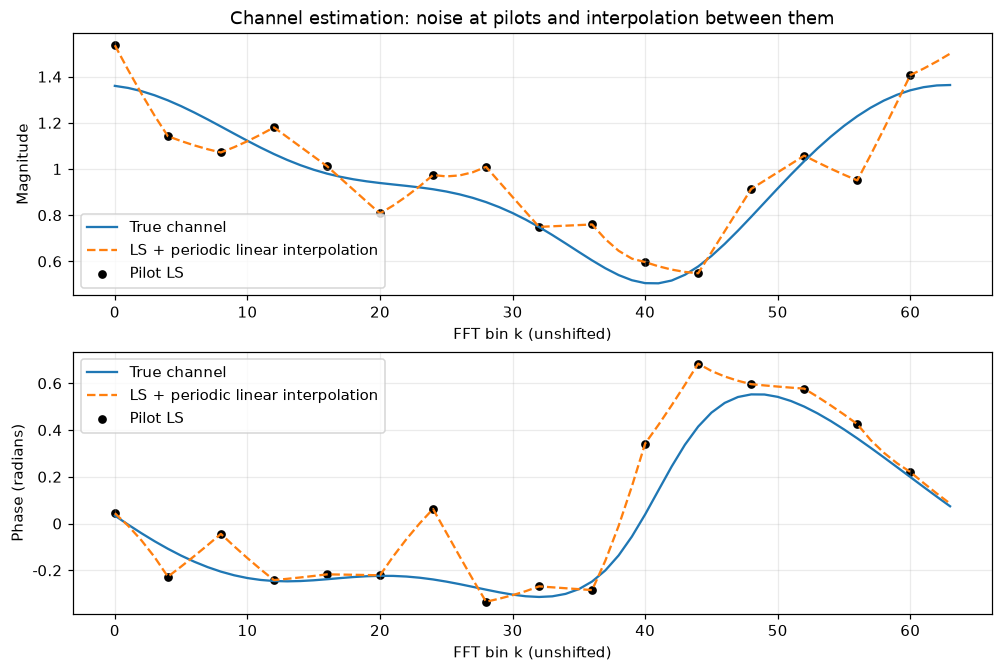

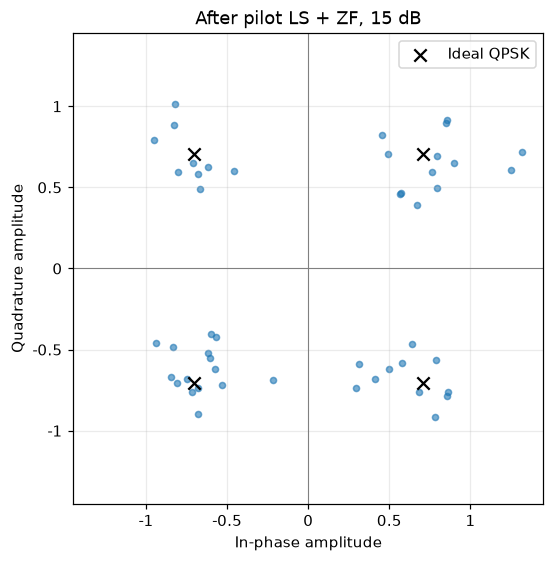

Single-frame LS BER: 0.0 NMSE: 0.018549758958217345


In [10]:
ls_frame = simulate_frame(config, np.random.default_rng(SEED), csi="ls")
np.testing.assert_array_equal(ls_frame.received_grid, perfect_frame.received_grid)
np.testing.assert_allclose(
    ls_frame.estimated_channel[config.pilot_indices],
    ls_frame.received_grid[config.pilot_indices] / config.pilot_value,
)
figure = plot_channel_estimate(
    ls_frame.channel_frequency_response, ls_frame.estimated_channel, config.pilot_indices
)
figure.savefig(DEMO_DIR / "channel_estimate.png", dpi=160)
plt.show()
figure = plot_constellation(
    ls_frame.equalized_grid[config.data_indices], "After pilot LS + ZF, 15 dB"
)
figure.savefig(DEMO_DIR / "after_equalization.png", dpi=160)
plt.show()
print("Single-frame LS BER:", ls_frame.ber, "NMSE:", ls_frame.nmse)

## 11. BER over many frames

`BER=wrong payload bits/total payload bits`. One 96-bit frame is fine for debugging,
but it can't measure a small BER. So I run 5,000 frames per SNR (480,000 payload bits),
and both receivers decode exactly the same frames. The random generator restarts from
the same seed at every SNR, which makes the curves smoother. The frame code is in
`simulation.py` and the sweep is in `experiments.py`. The CSV and JSON files keep the
counts, settings, seeds and package versions.

In [11]:
snr_values = np.arange(0, 31, 5, dtype=float)
sweep = run_ber_sweep(config, snr_values, num_frames=5000, seed=SEED)
print(format_sweep_table(sweep))
NOTEBOOK_RESULTS = ROOT / "results" / "notebook_fixed"
save_sweep(sweep, NOTEBOOK_RESULTS)
assert all(
    a.ber_perfect >= b.ber_perfect for a, b in zip(sweep.points[:-1], sweep.points[1:], strict=True)
)
assert sweep.points[0].ber_perfect < sweep.points[0].ber_ls

SNR dB | BER perfect | BER LS      | NMSE LS     | errors perfect/LS | bits
   0.0 |      0.1746 |      0.2497 |      0.6873 |   83814/119852  | 480000
   5.0 |     0.06117 |      0.1005 |      0.2174 |   29360/48232   | 480000
  10.0 |    0.008596 |     0.01835 |     0.06881 |    4126/8807    | 480000
  15.0 |   0.0002021 |   0.0009083 |     0.02182 |      97/436     | 480000
  20.0 |           0 |           0 |    0.006962 |       0/0       | 480000
  25.0 |           0 |           0 |    0.002262 |       0/0       | 480000
  30.0 |           0 |           0 |   0.0007761 |       0/0       | 480000


## 12. BER versus SNR

Nonzero BER values are plotted on a log scale. When a receiver has no errors, I draw a
downward triangle at `1-0.05^(1/N_bits)`, which is a rough 95% upper bound. Bits in the
same faded frame tend to fail together, so this bound is only approximate and I use it
as a marker, not a real confidence interval. Zero errors doesn't mean the BER is
really zero, and two receivers that both have zero errors can't be ranked. Measuring
lower BER would need more bits.

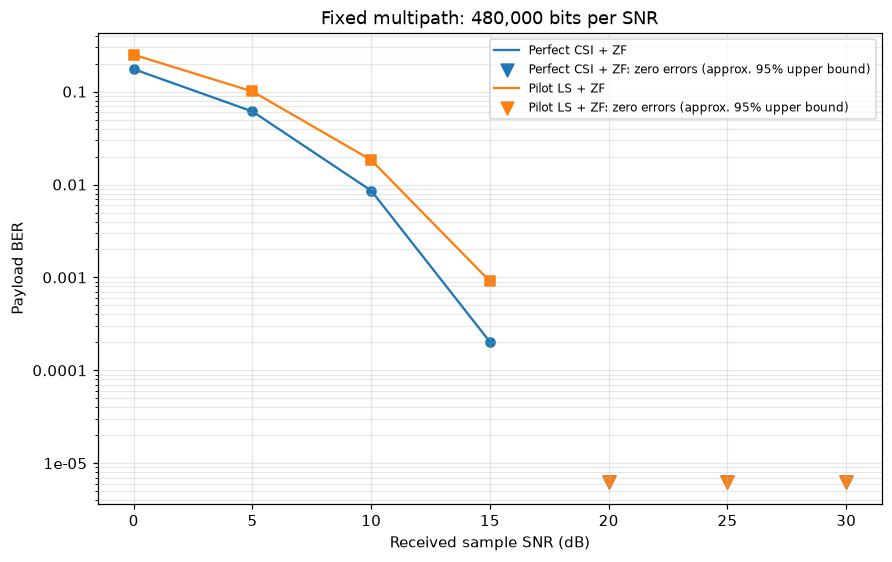

Zero-error display bound: 6.241089427557827e-06


In [12]:
figure = plot_ber_sweep(sweep)
figure.savefig(NOTEBOOK_RESULTS / "ber_vs_snr.png", dpi=160)
plt.show()
print("Zero-error display bound:", sweep.points[0].zero_error_upper_bound)

## 13. NMSE versus SNR

`NMSE=||H-H_hat||^2/||H||^2` measures how close the channel estimate is, here over all
FFT bins. I average NMSE per frame in **linear** units and only then convert to dB.
Less pilot noise lowers the NMSE, but straight-line interpolation leaves a small error
even with no noise. A low NMSE doesn't automatically mean a low BER: a small error
near a weak bin can hurt a lot after ZF.

Noiseless LS interpolation NMSE: 8.84692451467201e-05
Floor in dB: -40.532076782785865


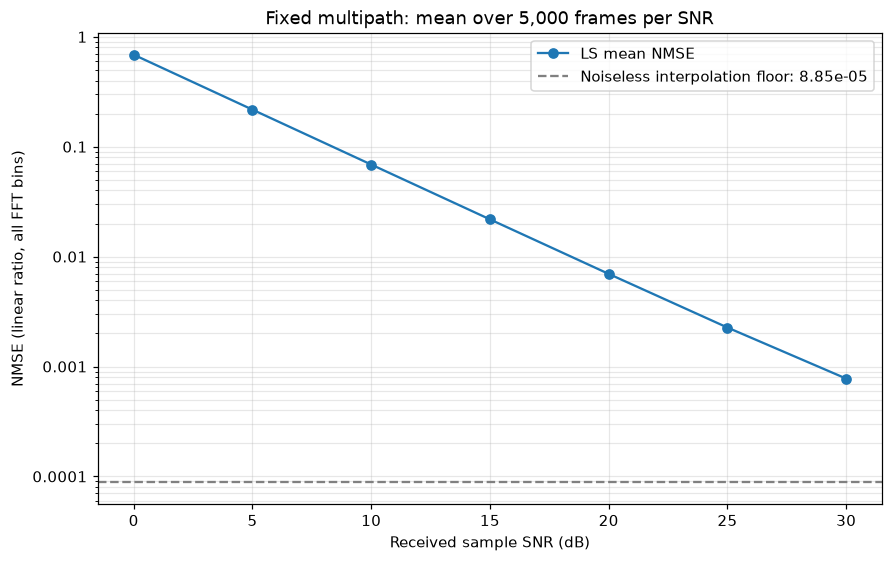

In [13]:
noiseless_estimate = ls_channel_estimate(
    true_channel * config.pilot_value, config.pilot_indices, config.pilot_value
)
interpolation_floor = normalized_mean_squared_error(true_channel, noiseless_estimate)
print("Noiseless LS interpolation NMSE:", interpolation_floor)
print("Floor in dB:", 10 * np.log10(interpolation_floor))
assert all(a.nmse_ls > b.nmse_ls for a, b in zip(sweep.points[:-1], sweep.points[1:], strict=True))
figure = plot_nmse_sweep(sweep)
figure.savefig(NOTEBOOK_RESULTS / "nmse_vs_snr.png", dpi=160)
plt.show()

## 14. What I found, and adding Rayleigh fading

- Higher SNR makes the constellations tighter and generally lowers both BER and LS NMSE.
- Perfect CSI has no pilot noise and no interpolation error. Its advantage shows up
  wherever both receivers have enough errors to compare.
- LS is held back by noisy pilots, the channel curving between pilots, and ZF
  boosting the noise in weak bins. The small error floor comes from interpolation,
  not from an FFT mistake.
- Better estimators like LMMSE, and later neural networks, are the next steps. They
  are **not part of this notebook**. Any later comparison has to use the same channel
  and noise settings and keep training and test channels apart.

I only added random Rayleigh taps after the seven basic checks passed. Each one-symbol
frame gets a new channel that stays fixed during the symbol, with
`h_l~CN(0,p_l/sum p_l)`. I normalize the **average** tap energy, not each channel.
This is a simple random channel, not a 3GPP model.

Because the noise power is set from each frame's received power, this experiment
holds the received SNR fixed and the noise follows the fade. So it shows the effect
of frequency selectivity at a given received SNR; it is not an outage test with a
fixed transmit power and a fixed noise level.

In [14]:
rayleigh_config = replace(config, channel_model="rayleigh", snr_db=np.inf)
rayleigh_gate = simulate_frame(rayleigh_config, np.random.default_rng(SEED), csi="perfect")
assert rayleigh_gate.ber == 0
rayleigh_sweep = run_ber_sweep(rayleigh_config, [0, 10, 20, 30], num_frames=2000, seed=SEED)
print(format_sweep_table(rayleigh_sweep))
print("Before next stage: explain Gray mapping, unitary FFT energy, CP >= L-1, Y=HX+W,")
print("complex-noise variance, pilot LS, periodic interpolation, ZF noise enhancement,")
print("and the difference between BER and NMSE without relying on this notebook.")
plt.close("all")

SNR dB | BER perfect | BER LS      | NMSE LS     | errors perfect/LS | bits
   0.0 |      0.1904 |      0.2635 |       0.679 |   36558/50586   | 192000
  10.0 |     0.02758 |     0.04401 |     0.06895 |    5296/8449    | 192000
  20.0 |     0.00276 |    0.004469 |     0.00792 |     530/858     | 192000
  30.0 |   0.0003698 |   0.0008437 |    0.001809 |      71/162     | 192000
Before next stage: explain Gray mapping, unitary FFT energy, CP >= L-1, Y=HX+W,
complex-noise variance, pilot LS, periodic interpolation, ZF noise enhancement,
and the difference between BER and NMSE without relying on this notebook.
